# ICS 635 · Final Project
## Clean-Energy Momentum Forecast

**Team:** Jiyeon Chun, Kylie Higashionna, Matt Ong

We want to forecast each U.S. state's renewable share of electricity generation one month
ahead, and determine which historical generation and seasonal features matter most for making
accurate predictions. We will compare different machine learning and time-series models to see
whether they can outperform a simple seasonal baseline.

- **Data:** EIA Open Data, Electric Power Operations (monthly), "Utility Scale Electricity Net Generation", from EIA's bulk file
- **Target:** renewable generation (REN = AOR + HYC) / total generation (ALL), all sectors (sector ID 99)
- **Unit of analysis:** one row per state-month, 50 states, one global model

## Setup

This notebook uses Python 3.13. The next cell installs the packages listed in `requirements.txt`
into the active kernel. If it changes any installed package, restart the kernel before continuing.
If you create your environment with `uv`, use `uv venv --seed` so that it includes `pip`.

### Data

The notebook reads one file, `data/eia_generation_monthly_combined.csv`, which is included in this
repository. It is EIA's bulk electricity file with 62 blank values filled from EIA's API (see below).
The bulk file needs no API key:

- **Source:** https://www.eia.gov/opendata/bulk/ELEC.zip, listed on https://www.eia.gov/opendata/bulk.php
- **Version used:** last modified by EIA on 2026-10-23
- **SHA-256 of `ELEC.zip`:** `73e289b5e23c28922f1c47686282f00e1459abee0376242862f17bfc2ada1f6b`

To rebuild the CSV from EIA yourself, run this from the repository folder:

```
python download_eia_data.py
```

It downloads `ELEC.zip` (about 300 MB) into `data/`, prints the file's date and SHA-256, and writes
the CSV. If you already downloaded `ELEC.zip` in a browser, run
`python download_eia_data.py --zip path/to/ELEC.zip` instead.

EIA updates the bulk file about once a month. If the SHA-256 printed by the script differs from the
one above, your download is a newer version and may include later months or revised values.

### Filling blanks with `fill_ren_gaps.py`

In the bulk file, one of the two parts of `REN` (`AOR` or `HYC`) is blank in 62 state-months, mostly
hydro in the preliminary 2025-2026 months. EIA's API publishes `REN` for those months, so
`fill_ren_gaps.py` sets the blank part to `REN` minus the other part. It made one API call (`REN` for the
14 affected states, 2012-01 to 2026-08) and saved the result in `data/eia_ren_api_gaps.csv`, so
rebuilding the combined file needs no key:

```
python fill_ren_gaps.py
```

The `source` column marks each value as `eia_bulk` or `derived_from_api_ren`.

In [1]:
%pip install -q -r requirements.txt

Note: you may need to restart the kernel to use updated packages.


In [2]:
# --- Imports ---
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.model_selection import ParameterGrid
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from xgboost import XGBRegressor

# --- Paths ---
DATA_DIR = Path("data")
RAW_PATH = DATA_DIR / "eia_generation_monthly_combined.csv"  # bulk file + 62 values filled by fill_ren_gaps.py
PANEL_PATH = DATA_DIR / "state_month_panel.csv"           # written by this notebook

# --- Reproducibility ---
SEED = 635
np.random.seed(SEED)

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", None)   # show model settings in full

## 1. Data Preprocessing

This section starts from the data as EIA publishes it and shows every change we make to it:
one row per location, fuel, and month becomes one row per state-month with a renewable share.

### 1.1 Load and inspect the raw data

All of our data comes from `eia_generation_monthly_combined.csv`: the
[EIA bulk file](https://www.eia.gov/opendata/bulk/ELEC.zip) as `download_eia_data.py` saves it, with 62 blank
values filled by `fill_ren_gaps.py`. It keeps EIA's monthly net generation
series for all sectors (sector 99) from 2001 onward, using the same column names as EIA's API.

In [3]:
raw = pd.read_csv(RAW_PATH, dtype={"sectorid": str})

# --- Size, coverage, and missing values ---
display(pd.Series({
    "rows": len(raw),
    "columns": raw.shape[1],
    "first month": raw["period"].min(),
    "last month": raw["period"].max(),
    "locations": raw["location"].nunique(),
    "fuel codes": raw["fueltypeid"].nunique(),
    "sectors": raw["sectorid"].nunique(),
    "blank generation values": int(raw["generation"].isna().sum()),
    "values filled from API REN": int((raw["source"] == "derived_from_api_ren").sum()),
    "duplicate location-fuel-months": int(raw.duplicated(["location", "fueltypeid", "period"]).sum()),
}, name="Raw EIA data").to_frame())

display(raw.head())

# --- Column types and meaning ---
column_info = {
    "period":              ("identifier", "YYYY-MM",          "year and month"),
    "location":            ("categorical", "code",            "state, census region, or US total"),
    "stateDescription":    ("text", "none",                   "location name"),
    "sectorid":            ("categorical", "code",            "producer category; 99 = all sectors"),
    "sectorDescription":   ("text", "none",                   "sector name"),
    "fueltypeid":          ("categorical", "code",            "energy source, including aggregates such as ALL"),
    "fuelTypeDescription": ("text", "none",                   "fuel name"),
    "generation":          ("numeric", "thousand MWh",        "net generation; blank = no value published"),
    "generation-units":    ("text", "none",                   "unit label"),
    "source":              ("categorical", "label",           "eia_bulk, or derived_from_api_ren if filled"),
}
display(pd.DataFrame(column_info, index=["type", "unit", "meaning"]).T)

# --- Fuel codes in the raw file ---
(raw.groupby(["fueltypeid", "fuelTypeDescription"])
    .agg(rows=("generation", "size"), blanks=("generation", lambda s: s.isna().sum()),
         first_month=("period", "min"))
    .reset_index())

,Raw EIA data
rows,261961
columns,10
first month,2001-01
last month,2026-08
locations,62
fuel codes,20
sectors,1
blank generation values,895
values filled from API REN,62
duplicate location-fuel-months,0


,period,location,stateDescription,sectorid,sectorDescription,fueltypeid,fuelTypeDescription,generation,generation-units,source
0,2026-08,US,United States,99,All Sectors,SUN,all utility-scale solar,38818.73419,thousand megawatthours,eia_bulk
1,2026-07,US,United States,99,All Sectors,SUN,all utility-scale solar,41043.99639,thousand megawatthours,eia_bulk
2,2026-06,US,United States,99,All Sectors,SUN,all utility-scale solar,38526.99908,thousand megawatthours,eia_bulk
3,2026-05,US,United States,99,All Sectors,SUN,all utility-scale solar,36368.64302,thousand megawatthours,eia_bulk
4,2026-04,US,United States,99,All Sectors,SUN,all utility-scale solar,30986.14115,thousand megawatthours,eia_bulk


,type,unit,meaning
period,identifier,YYYY-MM,year and month
location,categorical,code,"state, census region, or US total"
stateDescription,text,none,location name
sectorid,categorical,code,producer category; 99 = all sectors
sectorDescription,text,none,sector name
fueltypeid,categorical,code,"energy source, including aggregates such as ALL"
fuelTypeDescription,text,none,fuel name
generation,numeric,thousand MWh,net generation; blank = no value published
generation-units,text,none,unit label
source,categorical,label,"eia_bulk, or derived_from_api_ren if filled"


,fueltypeid,fuelTypeDescription,rows,blanks,first_month
0,ALL,all fuels,19096,0,2001-01
1,AOR,other renewables (total),18853,0,2001-01
2,COW,coal,18059,2,2001-01
3,DPV,small-scale solar photovoltaic,9400,165,2014-01
4,GEO,geothermal,3007,3,2001-01
5,HPS,hydro-electric pumped storage,8624,0,2001-01
6,HYC,conventional hydroelectric,18172,0,2001-01
7,NG,natural gas,18668,19,2001-01
8,NUC,nuclear,12332,0,2001-01
9,OOG,other gases,11110,11,2001-01


### Analysis

**Raw data.** The generation file has 261,961 rows across 62 locations, 20 fuel codes, and
2001-01 to 2026-08, with no duplicates. 957 values are blank in the bulk file; 62 of them are filled from EIA's API, so 895
remain blank.

**There is no `REN` series, so we compute it.** The bulk file has no total-renewables (`REN`) code.
EIA's renewables total is conventional hydroelectric (`HYC`) plus "other renewables (total)" (`AOR`:
wind, utility-scale solar, geothermal, and biomass), so we use `REN = AOR + HYC`. Neither part works on
its own: for California in July 2013, `AOR` is 3,422 thousand MWh, while `AOR + HYC` is 6,615. Both
parts go back to 2001, so this also gives us `REN` for 2001-2002. EIA's API only has `REN` from 2003-01.

We checked this formula once against the `REN` values from EIA's API, which needs a key, so it is not
part of this notebook. That download covered Hawaii and California from 2003 to 2026, but
the other 48 states only from 2003 to 2009. For the 4,487 state-months it covered, 4,439 agree within
0.01 thousand MWh. The largest gap is 4.5 thousand MWh (Arizona, July 2003), which is 0.07 percentage
points of that state's renewable share.

**Missing values are not all the same.** A month with *no row* means EIA has no series for that fuel
yet, as with Delaware's renewables before 2006. A row with a *blank value* means a series exists but
nothing was published for that month. Section 1.2 treats these differently.

**62 blanks are filled from EIA's API.** In 62 state-months, one part of `REN` is blank: hydro (`HYC`) in
60 of them, all in preliminary 2025-2026 months across 13 states, and `AOR` for Alaska in two months
of 2012. Without a fix these months have no target, and 55 of them fall in the test period, including
Hawaii from January to July 2026. EIA's API publishes `REN` for these months, so `fill_ren_gaps.py` sets
the blank part to `REN` minus the other part. For these 14 states from 2012 on, the bulk file's
`AOR + HYC` equals the API's `REN` in all 2,402 state-months where both parts exist, so both files come
from the same EIA release.

The filled values are EIA's own totals, but some are far from the same month in earlier years: South
Carolina's hydro in July 2026 is 0.18 times its average for July 2023-2025. The bulk file probably left
these blank because EIA considered the preliminary numbers unreliable. Section 1.2 marks the affected
state-months (`ren_filled`), and we report test error with and without them.

**Rooftop solar is not included.** The target covers utility-scale generation only. EIA's estimate of
small-scale solar, mostly rooftop panels (`DPV`), is in the raw file but is not part of `REN` or `ALL`,
and we leave it out for three reasons:

- **It starts in 2014.** Adding it would put an artificial jump into every state's share in January 2014,
  in the middle of our 2002-2018 training period.
- **It is an estimate.** EIA models it from installed capacity instead of measuring it, and 165 of its
  values are blank.
- **It would change the target.** The proposal defines the target as `REN / ALL` for utility-scale
  generation.

This matters most in states with a lot of rooftop solar. In 2024, including it would raise the typical
state's renewable share by about 0.5 percentage points, but Massachusetts's would go up 13 points (from
20% to 33%) and Hawaii's 12 points (from 21% to 33%). Our shares therefore understate renewables most in
those states.

### 1.2 Transform the raw data into the state-month table

| Step | Change | Why |
|---|---|---|
| 1 | Keep the 50 states | Drops DC, census regions, and the US total, which would double count states |
| 2 | Keep sector 99 | REN and ALL must cover the same producers |
| 3 | Keep the fuels we use | The rest are subsets or are not used as features |
| 4 | Keep months through 2026-07 | The proposal's test period ends there |
| 5 | Pivot to one row per state-month | Models need one row per example |
| 6 | Add `REN = AOR + HYC` | The bulk file has no `REN` series |
| 7 | Compute `renewable_share` | The prediction target |

In [4]:
STATES = ("AL AK AZ AR CA CO CT DE FL GA HI ID IL IN IA KS KY LA ME MD MA MI MN MS MO "
          "MT NE NV NH NJ NM NY NC ND OH OK OR PA RI SC SD TN TX UT VT VA WA WV WI WY").split()
assert len(STATES) == 50

FUELS = ["ALL", "AOR", "HYC", "WND", "SUN", "COW", "NG", "NUC"]
LAST_MONTH = pd.Timestamp("2026-07-01")

# Row count after each step, so every change to the data is visible
steps = [("Raw EIA file", len(raw), "one row per location, fuel, and month")]

# --- Steps 1-4: filter the rows ---
rows = raw[raw["location"].isin(STATES)]
steps.append(("1. Keep the 50 states", len(rows), "drops DC, census regions, and US"))

rows = rows[rows["sectorid"] == "99"]
steps.append(("2. Keep sector 99", len(rows), "same producers in REN and ALL"))

rows = rows[rows["fueltypeid"].isin(FUELS)]
steps.append(("3. Keep the fuels we use", len(rows), ", ".join(FUELS)))

rows = rows.assign(date=pd.to_datetime(rows["period"], format="%Y-%m"))
rows = rows[rows["date"] <= LAST_MONTH]
steps.append(("4. Keep months through 2026-07", len(rows), "end of the proposal's test period"))

# --- Step 5: pivot to one row per state-month ---
all_months = pd.date_range("2001-01-01", LAST_MONTH, freq="MS")
full_index = pd.MultiIndex.from_product([STATES, all_months], names=["location", "date"])
keys = dict(index=["location", "date"], columns="fueltypeid")

# No row = no series yet, so generation is 0. Blank value = not published, so it stays missing.
wide = rows.pivot(values="generation", **keys).reindex(index=full_index, columns=FUELS)
is_blank = (rows.assign(blank=rows["generation"].isna())
            .pivot(values="blank", **keys)
            .reindex(index=full_index, columns=FUELS)
            .eq(True))
wide = wide.fillna(0).mask(is_blank)

# Mark state-months that use a value filled from the API, so results can be checked without them
filled = rows.loc[rows["source"] == "derived_from_api_ren", ["location", "date"]].drop_duplicates()
wide["ren_filled"] = wide.index.isin(pd.MultiIndex.from_frame(filled))
print(f"{wide['ren_filled'].sum()} state-months use a value filled from the API")
steps.append(("5. Pivot to one row per state-month", len(wide), "50 states x 307 months"))

assert len(wide) == 50 * 307
assert wide["ALL"].notna().all() and (wide["ALL"] > 0).all()
wide.head()

57 state-months use a value filled from the API


fueltypeid                 ALL        AOR       HYC  WND  SUN       COW  \
location date                                                             
AL       2001-01-01  11326.642  401.16759   727.118  0.0  0.0  6557.913   
         2001-02-01   9576.039  331.77037   922.210  0.0  0.0  5479.455   
         2001-03-01   9364.445  355.48069  1299.668  0.0  0.0  5392.921   
         2001-04-01   7714.348  346.60869   696.398  0.0  0.0  4619.950   
         2001-05-01  10048.668  306.45667   394.587  0.0  0.0  5985.862   

fueltypeid                NG       NUC  ren_filled  
location date                                       
AL       2001-01-01  566.478  2940.300       False  
         2001-02-01  276.610  2515.933       False  
         2001-03-01  389.456  1873.313       False  
         2001-04-01  491.732  1459.636       False  
         2001-05-01  640.437  2677.375       False

In [5]:
# --- Step 6: add REN = AOR + HYC (the bulk file has no REN series) ---
panel = wide.copy()
panel["REN"] = panel["AOR"] + panel["HYC"]   # stays missing if either part is blank
steps.append(("6. Add REN = AOR + HYC", len(panel), "bulk file has no REN series"))

print(f"REN is missing for {panel['REN'].isna().sum()} state-months because AOR or HYC is blank")

# --- Step 7: the target ---
panel["share_unclipped"] = panel["REN"] / panel["ALL"]
print("Shares above 1:")
display(panel.loc[panel["share_unclipped"] > 1, ["REN", "ALL", "share_unclipped"]])

panel["renewable_share"] = panel["share_unclipped"].clip(upper=1)
steps.append(("7. Compute renewable_share", len(panel), "REN / ALL, capped at 1"))

# Fuel mix: each fuel as a share of the state's generation. Used for lag features in Section 1.3.
for name, fuel in {"coal": "COW", "gas": "NG", "nuclear": "NUC", "hydro": "HYC",
                   "wind": "WND", "solar": "SUN"}.items():
    panel[f"{name}_share"] = panel[fuel] / panel["ALL"]
panel["other_ren_share"] = (panel["AOR"] - panel["WND"] - panel["SUN"]) / panel["ALL"]

panel = panel.reset_index()

# --- Every step in one table ---
pd.DataFrame(steps, columns=["step", "rows", "note"]).set_index("step")

REN is missing for 0 state-months because AOR or HYC is blank
Shares above 1:


fueltypeid                 REN        ALL  share_unclipped
location date                                             
VT       2019-05-01  239.47910  239.47089         1.000034
         2019-09-01  114.11276  113.99873         1.001000
         2019-11-01  167.33872  167.29958         1.000234
         2020-07-01  157.02748  156.58850         1.002803
         2020-08-01  120.19553  120.10341         1.000767
         2020-09-01   84.34279   84.18422         1.001884
         2020-10-01  169.42709  169.20641         1.001304
         2020-11-01  174.00472  173.87403         1.000752
         2025-05-01  252.35800  252.34744         1.000042

,rows,note
step,,
Raw EIA file,261961,"one row per location, fuel, and month"
1. Keep the 50 states,203695,"drops DC, census regions, and US"
2. Keep sector 99,203695,same producers in REN and ALL
3. Keep the fuels we use,103612,"ALL, AOR, HYC, WND, SUN, COW, NG, NUC"
4. Keep months through 2026-07,103249,end of the proposal's test period
5. Pivot to one row per state-month,15350,50 states x 307 months
6. Add REN = AOR + HYC,15350,bulk file has no REN series
7. Compute renewable_share,15350,"REN / ALL, capped at 1"


In [6]:
# --- One worked example: Hawaii, July 2024 ---
print("Before: rows in the raw EIA file")
display(raw.loc[(raw["location"] == "HI") & (raw["period"] == "2024-07") & raw["fueltypeid"].isin(FUELS),
                ["period", "location", "sectorid", "fueltypeid", "fuelTypeDescription", "generation"]])

print("After: one row in our table")
panel.loc[(panel["location"] == "HI") & (panel["date"] == "2024-07-01"),
          ["location", "date", "ALL", "AOR", "HYC", "REN", "renewable_share"]]

Before: rows in the raw EIA file


,period,location,sectorid,fueltypeid,fuelTypeDescription,generation
11122,2024-07,HI,99,SUN,all utility-scale solar,73.16162
36955,2024-07,HI,99,AOR,other renewables (total),185.48170
120170,2024-07,HI,99,HYC,conventional hydroelectric,7.98900
133847,2024-07,HI,99,WND,wind,68.38562
234256,2024-07,HI,99,ALL,all fuels,795.82150


After: one row in our table


fueltypeid,location,date,ALL,AOR,HYC,REN,renewable_share
3352,HI,2024-07-01,795.8215,185.4817,7.989,193.4707,0.243108


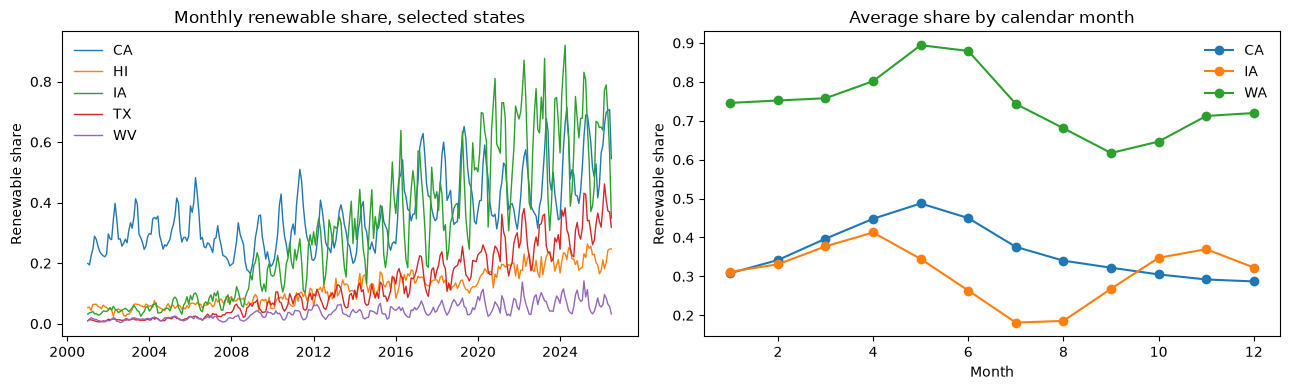

,mean,min,max
location,,,
DE,0.022,0.000,0.128
OH,0.023,0.003,0.134
NJ,0.023,0.011,0.057
MS,0.031,0.017,0.099
PA,0.033,0.012,0.069
CT,0.036,0.018,0.093
FL,0.036,0.015,0.150
LA,0.038,0.020,0.071
WV,0.040,0.004,0.141


In [7]:
# --- What the target looks like ---
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

for state in ["CA", "HI", "IA", "TX", "WV"]:
    series = panel[panel["location"] == state]
    axes[0].plot(series["date"], series["renewable_share"], label=state, linewidth=1)
axes[0].set(title="Monthly renewable share, selected states", ylabel="Renewable share")
axes[0].legend(frameon=False)

by_month = (panel[panel["location"].isin(["CA", "IA", "WA"])]
            .groupby(["location", panel["date"].dt.month])["renewable_share"].mean().unstack(0))
by_month.plot(ax=axes[1], marker="o")
axes[1].set(title="Average share by calendar month", xlabel="Month", ylabel="Renewable share")
axes[1].legend(frameon=False, title=None)

plt.tight_layout()
plt.show()

panel.groupby("location")["renewable_share"].agg(["mean", "min", "max"]).sort_values("mean").round(3)

### 1.3 Features and data splits

Each row predicts one state's renewable share for one month, month *t*. Every feature uses only data
up to the end of month *t − 1*, so nothing from the month being predicted, or later, enters a feature.

| Group | Feature | Definition |
|---|---|---|
| State | `location` | State code, so one global model can learn state-level differences |
| History | `share_lag1`, `share_lag2`, `share_lag3` | Renewable share 1, 2, and 3 months earlier |
| History | `share_change_12m` | `share_lag1` minus the share 13 months earlier: the trend over the past year |
| History | `share_mean_3m`, `share_mean_12m` | Average share over the previous 3 and 12 months |
| History | `<fuel>_share_lag1` | Last month's share of coal, gas, nuclear, hydro, wind, solar, and other renewables |
| History | `log_total_gen_lag1` | Log of last month's total generation, a measure of the state's size |
| Seasonal | `share_lag12` | Share in the same month one year earlier. This is also the seasonal naive baseline |
| Seasonal | `month` | Calendar month of the month being predicted |

The ablation study compares models trained on **state + history** with models trained on
**state + history + seasonal**, as in the proposal. The seasonal group holds the two features that
tell the model *which time of year* it is predicting: the calendar month, and the share in that
same month last year, which the proposal also calls the seasonal forecast. `share_mean_12m` and
`share_change_12m` stay in history. Each spans a full year, so the seasonal pattern cancels out
and they measure the state's level and trend instead.

The splits use the same date boundaries for every state, as in the proposal:

| Split | Months | State-months |
|---|---|---|
| Train | 2002-01 to 2018-12 | 10,200 |
| Validation | 2019-01 to 2022-12 | 2,400 |
| Test | 2023-01 to 2026-07 (2026 values are preliminary) | 2,150 |

2001 is not in any split. It only supplies the lag values for the first training months.

In [8]:
# --- Features: each one is known by the end of the month before the one we predict ---
df = panel.sort_values(["location", "date"]).reset_index(drop=True)
df.columns.name = None
assert (df.groupby("location").size() == len(all_months)).all()   # no gaps, so shift(k) = k months earlier

by_state = df.groupby("location")
FUEL_SHARES = ["coal_share", "gas_share", "nuclear_share", "hydro_share",
               "wind_share", "solar_share", "other_ren_share"]

for k in (1, 2, 3, 12):
    df[f"share_lag{k}"] = by_state["renewable_share"].shift(k)
df["share_change_12m"] = df["share_lag1"] - by_state["renewable_share"].shift(13)
for window in (3, 12):
    df[f"share_mean_{window}m"] = by_state["renewable_share"].transform(
        lambda s: s.shift(1).rolling(window, min_periods=1).mean())
for col in FUEL_SHARES:
    df[f"{col}_lag1"] = by_state[col].shift(1)
df["log_total_gen_lag1"] = np.log1p(by_state["ALL"].shift(1))
df["month"] = df["date"].dt.month

STATE_FEATURES = ["location"]
HISTORY_FEATURES = (["share_lag1", "share_lag2", "share_lag3", "share_change_12m",
                     "share_mean_3m", "share_mean_12m", "log_total_gen_lag1"]
                    + [f"{c}_lag1" for c in FUEL_SHARES])
SEASONAL_FEATURES = ["share_lag12", "month"]   # which time of year is being predicted
TARGET = "renewable_share"
BASELINE = "share_lag12"   # seasonal naive forecast: same month one year earlier

df[["location", "date", TARGET] + HISTORY_FEATURES + SEASONAL_FEATURES].head(14)

,location,date,renewable_share,share_lag1,share_lag2,share_lag3,share_change_12m,share_mean_3m,share_mean_12m,log_total_gen_lag1,coal_share_lag1,gas_share_lag1,nuclear_share_lag1,hydro_share_lag1,wind_share_lag1,solar_share_lag1,other_ren_share_lag1,share_lag12,month
0,AK,2001-01-01,0.177306,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1
1,AK,2001-02-01,0.165123,0.177306,NaN,NaN,NaN,0.177306,0.177306,6.382061,0.079477,0.622764,0.0,0.177158,0.000147,0.0,0.000000,NaN,2
2,AK,2001-03-01,0.170195,0.165123,0.177306,NaN,NaN,0.171215,0.171215,6.304754,0.098973,0.611564,0.0,0.164988,0.000135,0.0,0.000000,NaN,3
3,AK,2001-04-01,0.173289,0.170195,0.165123,0.177306,NaN,0.170875,0.170875,6.376923,0.088432,0.585674,0.0,0.170057,0.000138,0.0,0.000000,NaN,4
4,AK,2001-05-01,0.175781,0.173289,0.170195,0.165123,NaN,0.169536,0.171478,6.193789,0.076919,0.593516,0.0,0.173144,0.000145,0.0,0.000000,NaN,5
5,AK,2001-06-01,0.242670,0.175781,0.173289,0.170195,NaN,0.173088,0.172339,6.185564,0.084562,0.584848,0.0,0.175639,0.000142,0.0,0.000000,NaN,6
6,AK,2001-07-01,0.217981,0.242670,0.175781,0.173289,NaN,0.197247,0.184061,6.192371,0.080760,0.557524,0.0,0.242527,0.000143,0.0,0.000000,NaN,7
7,AK,2001-08-01,0.210221,0.217981,0.242670,0.175781,NaN,0.212144,0.188906,6.318833,0.099439,0.567916,0.0,0.217847,0.000134,0.0,0.000000,NaN,8
8,AK,2001-09-01,0.241972,0.210221,0.217981,0.242670,NaN,0.223624,0.191571,6.376380,0.111015,0.564276,0.0,0.210097,0.000124,0.0,0.000000,NaN,9
9,AK,2001-10-01,0.232880,0.241972,0.210221,0.217981,NaN,0.223391,0.197171,6.463288,0.092023,0.554872,0.0,0.241837,0.000134,0.0,0.000000,NaN,10


In [9]:
# --- Splits: the same date boundaries for every state ---
SPLITS = {"train":      ("2002-01-01", "2018-12-01"),
          "validation": ("2019-01-01", "2022-12-01"),
          "test":       ("2023-01-01", "2026-07-01")}
df["split"] = None
for name, (start, end) in SPLITS.items():
    df.loc[df["date"].between(start, end), "split"] = name
assert df.loc[df["split"].isna(), "date"].dt.year.eq(2001).all()   # only 2001 is left out

# Rows without a target cannot be trained on or scored
model_rows = df[df["split"].notna() & df[TARGET].notna()].reset_index(drop=True)

display(df[df["split"].notna()]
        .groupby("split", sort=False)
        .agg(first_month=("date", "min"), last_month=("date", "max"), state_months=("date", "size"),
             target_missing=(TARGET, lambda s: s.isna().sum()),
             filled_from_api=("ren_filled", "sum"))
        .assign(rows_used=model_rows.groupby("split").size()))

# Features can still be missing when an earlier month was blank. Section 2 fills them inside each
# model's pipeline, using values learned from the training split only.
print("Missing feature values in the rows we use:")
display(model_rows.groupby("split", sort=False)[HISTORY_FEATURES + SEASONAL_FEATURES]
        .agg(lambda s: s.isna().sum()).T.loc[lambda t: t.sum(axis=1) > 0])

,first_month,last_month,state_months,target_missing,filled_from_api,rows_used
split,,,,,,
train,2002-01-01,2018-12-01,10200,0,2,10200
validation,2019-01-01,2022-12-01,2400,0,0,2400
test,2023-01-01,2026-07-01,2150,0,55,2150


Missing feature values in the rows we use:


split,train,validation,test
share_change_12m,50,0,0
coal_share_lag1,1,0,0
gas_share_lag1,7,0,2
wind_share_lag1,5,1,2
solar_share_lag1,37,0,12
other_ren_share_lag1,42,1,13


In [10]:
# --- Check: Hawaii, July 2024 (the proposal's example) uses only earlier months ---
hi = df.set_index(["location", "date"])
july_2024 = hi.loc[("HI", pd.Timestamp("2024-07-01"))]
assert july_2024["share_lag1"] == hi.loc[("HI", pd.Timestamp("2024-06-01")), TARGET]
assert july_2024["share_lag12"] == hi.loc[("HI", pd.Timestamp("2023-07-01")), TARGET]
display(july_2024[[TARGET, "share_lag1", "share_lag12", "share_mean_3m", "share_change_12m", "month"]]
        .to_frame("HI, 2024-07"))

# --- The baseline to beat, on validation only. The test split stays untouched until the end ---
val = model_rows[model_rows["split"] == "validation"]
assert val[BASELINE].notna().all()
print(f"Seasonal naive baseline on validation: "
      f"MAE {mean_absolute_error(val[TARGET], val[BASELINE]):.4f}, "
      f"RMSE {mean_squared_error(val[TARGET], val[BASELINE]) ** 0.5:.4f}")

,"HI, 2024-07"
renewable_share,0.243108
share_lag1,0.251062
share_lag12,0.2343
share_mean_3m,0.231172
share_change_12m,0.019474
month,7


Seasonal naive baseline on validation: MAE 0.0314, RMSE 0.0510


### Analysis

**The splits match the proposal.** Train, validation, and test have 10,200, 2,400, and 2,150
state-months.

**Every state-month has a target.** With the 62 filled values, no `REN` is missing, so we score models
on all 2,150 test state-months. 55 of them use a filled value (`ren_filled`); we report test error with
and without those rows, so the results do not depend on the filled values.

**Some features are missing.** When an earlier month was blank, its lag is missing too. The largest
gap is `share_change_12m` in training, missing for 50 rows: all of them January 2002, which has no
value 13 months earlier. The fuel-mix lags are missing for at most 42 training rows. We leave these as missing here and fill them inside each model's pipeline in
Section 2.

**The baseline to beat.** On validation, the seasonal naive forecast is off by 0.031 on average (MAE),
or about 3 percentage points of renewable share. We do not score anything on the test split until the
final comparison.

## 2. Models

Every model predicts a state's renewable share for month *t* from the Section 1.3 features, and every
model and the baseline are scored on the same rows. Errors are in percentage points (pp) of renewable
share: an MAE of 2.0 means the predictions are off by 2 percentage points on average. This section only
uses the train and validation splits. The test split is scored once, at the end.

### 2.1 Seasonal naive baseline

The baseline predicts each state's share as its share in the same month one year earlier
(`share_lag12`). It needs no training.

In [11]:
# --- Rows and scoring used in all of Section 2 ---
FEATURES = STATE_FEATURES + HISTORY_FEATURES + SEASONAL_FEATURES
train = model_rows[model_rows["split"] == "train"]
val = model_rows[model_rows["split"] == "validation"]

def scores(y_true, y_pred):
    """MAE and RMSE in percentage points (pp) of renewable share."""
    return {"MAE (pp)": 100 * mean_absolute_error(y_true, y_pred),
            "RMSE (pp)": 100 * mean_squared_error(y_true, y_pred) ** 0.5}

val_predictions = {"Seasonal naive": val[BASELINE].to_numpy()}
pd.DataFrame({"Seasonal naive": scores(val[TARGET], val[BASELINE])}).T.round(2)

,MAE (pp),RMSE (pp)
Seasonal naive,3.14,5.1


### 2.2 Ridge, Random Forest, and XGBoost, tuned on validation

Each model runs inside one pipeline, so every step learns from the training rows only:

1. Fill missing numeric features with the training median.
2. Ridge only: standardize the numeric features, because its penalty depends on their scale.
3. One-hot encode `location` and `month`.
4. Fit the model, then clip its predictions to the range 0 to 1, since a share cannot leave it.

We fit every combination below on train, score it on validation, and keep the one with the lowest
validation MAE. This takes a few minutes.

| Model | Settings searched | Combinations |
|---|---|---|
| Ridge | `alpha`: 0.01, 0.1, 1, 10, 100 | 5 |
| Random Forest, 300 trees | `max_depth`: none, 20, 10; `min_samples_leaf`: 1, 5, 20; `max_features`: 0.15, 0.33, 1.0 | 27 |
| XGBoost, `subsample` and `colsample_bytree` 0.8 | `n_estimators`: 300, 600, 1000, 1500; `learning_rate`: 0.01, 0.03, 0.1; `max_depth`: 3, 5, 7 | 36 |

In [12]:
# --- One pipeline per model: fill missing values, encode, then fit ---
CATEGORICAL = ["location", "month"]

def make_model_pipeline(model, features, scale):
    """Missing numbers get the training median; state and month are one-hot encoded."""
    categorical = [f for f in features if f in CATEGORICAL]
    numeric = [f for f in features if f not in CATEGORICAL]
    numeric_steps = [("impute", SimpleImputer(strategy="median"))]
    if scale:
        numeric_steps.append(("scale", StandardScaler()))
    preprocess = ColumnTransformer([
        ("numeric", Pipeline(numeric_steps), numeric),
        ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical),
    ])
    return Pipeline([("preprocess", preprocess), ("model", model)])

def predict_share(pipeline, rows):
    """A share must lie between 0 and 1, so predictions are clipped to that range."""
    return np.clip(pipeline.predict(rows), 0, 1)

# name: (build the model from a parameter set, scale numeric features?, grid to search)
MODELS = {
    "Ridge": (lambda p: Ridge(**p), True,
              {"alpha": [0.01, 0.1, 1, 10, 100]}),
    "Random Forest": (lambda p: RandomForestRegressor(n_estimators=300, random_state=SEED, n_jobs=-1, **p), False,
                      {"max_depth": [None, 20, 10], "min_samples_leaf": [1, 5, 20], "max_features": [0.15, 0.33, 1.0]}),
    "XGBoost": (lambda p: XGBRegressor(subsample=0.8, colsample_bytree=0.8, random_state=SEED, n_jobs=-1, **p), False,
                {"n_estimators": [300, 600, 1000, 1500], "learning_rate": [0.01, 0.03, 0.1], "max_depth": [3, 5, 7]}),
}

# --- Tuning: fit on train, score on validation, keep the setting with the lowest MAE ---
tuning, BEST_PARAMS = [], {}
for name, (build, scale, grid) in MODELS.items():
    best_mae = np.inf
    for params in ParameterGrid(grid):
        pipeline = make_model_pipeline(build(params), FEATURES, scale).fit(train[FEATURES], train[TARGET])
        prediction = predict_share(pipeline, val[FEATURES])
        result = scores(val[TARGET], prediction)
        tuning.append({"model": name, "settings": ", ".join(f"{k}={v}" for k, v in params.items()), **result})
        if result["MAE (pp)"] < best_mae:
            best_mae, BEST_PARAMS[name], val_predictions[name] = result["MAE (pp)"], params, prediction

tuning = pd.DataFrame(tuning)
print(f"{len(tuning)} settings tried")
print("Three best settings per model:")
display(tuning.sort_values(["model", "MAE (pp)"]).groupby("model", sort=False).head(3)
        .round(3).reset_index(drop=True))

68 settings tried
Three best settings per model:


,model,settings,MAE (pp),RMSE (pp)
0,Random Forest,"max_depth=None, max_features=0.33, min_samples_leaf=1",2.477,3.962
1,Random Forest,"max_depth=None, max_features=1.0, min_samples_leaf=1",2.482,3.967
2,Random Forest,"max_depth=None, max_features=1.0, min_samples_leaf=5",2.483,3.998
3,Ridge,alpha=10,2.377,3.829
4,Ridge,alpha=1,2.389,3.833
5,Ridge,alpha=0.1,2.401,3.843
6,XGBoost,"learning_rate=0.01, max_depth=5, n_estimators=1000",2.374,3.839
7,XGBoost,"learning_rate=0.01, max_depth=5, n_estimators=600",2.377,3.808
8,XGBoost,"learning_rate=0.01, max_depth=5, n_estimators=1500",2.377,3.865


In [13]:
# --- Best setting of each model against the baseline, on validation ---
val_errors = pd.DataFrame({name: np.abs(val[TARGET].to_numpy() - pred)
                           for name, pred in val_predictions.items()}, index=val.index)
per_state_mae = val_errors.groupby(val["location"]).mean()

summary = pd.DataFrame({name: scores(val[TARGET], pred) for name, pred in val_predictions.items()}).T
summary["states beating baseline"] = (per_state_mae.lt(per_state_mae["Seasonal naive"], axis=0).sum()
                                      .astype(str) + " / 50")
summary.loc["Seasonal naive", "states beating baseline"] = "-"
summary["best setting"] = pd.Series({name: ", ".join(f"{k}={v}" for k, v in params.items())
                                    for name, params in BEST_PARAMS.items()})
summary.loc["Seasonal naive", "best setting"] = "-"
summary.round(2)

,MAE (pp),RMSE (pp),states beating baseline,best setting
Seasonal naive,3.14,5.10,-,-
Ridge,2.38,3.83,44 / 50,alpha=10
Random Forest,2.48,3.96,46 / 50,"max_depth=None, max_features=0.33, min_samples_leaf=1"
XGBoost,2.37,3.84,48 / 50,"learning_rate=0.01, max_depth=5, n_estimators=1000"


### Which features the tuned models rely on

Permutation importance shuffles one feature at a time in the validation rows and measures how much the
validation MAE rises. A large rise means the model depends on that feature. Each model is refit on train
with its best setting first. `location` is shuffled as one feature, not one column per state.

In [14]:
# --- Permutation importance on validation, for each model's best setting ---
def clipped_mae_score(pipeline, X, y):
    """Higher is better for scikit-learn scorers, so return minus the MAE in pp."""
    return -100 * mean_absolute_error(y, predict_share(pipeline, X))

importance = {}
for name, (build, scale, _) in MODELS.items():
    pipeline = make_model_pipeline(build(BEST_PARAMS[name]), FEATURES, scale).fit(train[FEATURES], train[TARGET])
    result = permutation_importance(pipeline, val[FEATURES], val[TARGET], scoring=clipped_mae_score,
                                    n_repeats=5, random_state=SEED)
    importance[name] = pd.Series(result.importances_mean, index=FEATURES)

importance = pd.DataFrame(importance).sort_values("XGBoost", ascending=False)
print("Rise in validation MAE (pp) when one feature is shuffled:")
importance.round(3)

Rise in validation MAE (pp) when one feature is shuffled:


,Ridge,Random Forest,XGBoost
share_lag1,4.210,6.785,11.243
share_mean_12m,4.396,2.502,3.482
share_lag12,5.243,2.187,2.403
month,0.205,0.136,0.427
gas_share_lag1,0.026,0.118,0.272
share_mean_3m,0.216,1.416,0.235
share_lag2,0.905,0.364,0.198
coal_share_lag1,0.015,0.075,0.183
wind_share_lag1,2.539,0.094,0.093
share_lag3,0.455,0.139,0.087


### Analysis

**All three models beat the baseline.** On validation, the seasonal naive forecast is off by 3.14 pp
on average. XGBoost reaches 2.37 pp and Ridge 2.38 pp, about 24% lower, and Random Forest reaches
2.48 pp, about 21% lower. Each model beats the baseline in 44 to 48 of the 50 states.

**XGBoost and Ridge are tied.** Their MAEs differ by 0.003 pp, and Ridge has the slightly lower RMSE
(3.83 against 3.84 pp). Validation does not separate them.

**Where the best settings sit in the search:**
- **Ridge:** `alpha` = 10 is in the middle of the values tried.
- **Random Forest:** the best trees are fully grown (no depth limit, leaves of one row), which is the
  edge of the grid but also the standard setting for a random forest. `max_features` = 0.33 is inside
  the range tried.
- **XGBoost:** 1,000 trees beat both 600 and 1,500, so the number of trees is inside the range. The
  learning rate, 0.01, is the lowest we tried. A lower rate would need even more trees, and 600, 1,000,
  and 1,500 trees all score within 0.003 pp of each other, so we expect little further gain.

**Three features carry most of the signal.** Shuffling `share_lag1`, `share_mean_12m`, or `share_lag12`
raises the validation MAE by 2 to 11 pp in every model. Shuffling `month` raises it by at most 0.4 pp,
because `share_lag12` already carries most of the seasonal pattern, and shuffling `location` by at most
0.04 pp, because the lags already describe each state. Ridge also relies on last month's hydro and wind
shares. Last month's hydro, wind, solar, and other-renewable shares add up to last month's renewable
share, so Ridge can split weight between them and `share_lag1`. Their individual importance should not
be over-read.

**These scores are slightly optimistic.** Each model's validation score comes from the setting that did
best on validation, so it overstates how well that model will do on new months. The test split, scored
once at the end, gives the fair comparison. Section 2.3 runs the ablation with these settings.